# How much of a coding-agent score is run-to-run luck?

- This notebook splits the score of 6 local coding agents (3 models x 2
  scaffolds) into the luck of the tasks and the luck of the runs, and checks
  which agents can be told apart
  - It reads the full scores: HumanEval+ (164 tasks) and MBPP+ (378 tasks),
    1 greedy run and 5 runs at temperature 0.8 per task
  - The analyses and the predictions were committed in `preregistration.md`
    before any of these scores existed
- The pedagogical arc:
  - The agents and their scores
  - How much of the variance of 1 run is run-to-run luck
  - Which pairs of agents differ, over the tasks and the runs
  - How often a leaderboard from 1 run puts the agents in the wrong order
  - Whether more runs or more tasks help more
  - How temperature changes run-to-run luck, in the public EvalPlus samples
  - Which predictions held

In [1]:
%load_ext autoreload
%autoreload 2

import logging

In [2]:
import helpers.hnotebook as hnotebook

import skill_vs_luck_runs_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmpwm27yq8b.json --HistoryManager.hist_file=:memory:


# Part 1: The agents and their scores

## Cell 1.1: Load the scores

- Each row is 1 solution: 1 model, 1 scaffold, 1 task, and 1 run
  - `source` is `local` for our runs and `evalplus` for the public samples,
    which only Part 6 uses
- The scaffolds share the first attempt, so `one_shot` and `repair` are paired

In [3]:
# Read the scores and the settings of the analysis.
SCORES_DIR = "data/coding_runs"
BENCHMARKS = ["humaneval", "mbpp"]
TEMPERATURE = 0.8
scores = utils.load_scores(SCORES_DIR)

print("scores.shape=", scores.shape)
display(utils.compute_score_table(scores[scores["source"] == "local"]).round(3))
# Outcome: at temperature 0.8 the one-shot plus scores are 74.1% (CodeQwen),
# 72.7% (OpenCoder), and 55.5% (DeepSeek) on HumanEval+, and 66.0%, 68.8%, and
# 48.7% on MBPP+; sampling costs 2 to 7 points against the greedy run.

scores.shape= (172312, 19)


n_tasks  n_runs  base_pass  plus_pass  mean_attempts  mean_seconds
source benchmark model                               temperature scaffold                                                                    
local  humaneval codeqwen:7b-chat-v1.5-q4_K_M        0.0         one_shot      164       1      0.829      0.787          1.000        15.558
                                                                 repair        164       1      0.835      0.787          1.116        16.986
                                                     0.8         one_shot      164       5      0.796      0.741          1.000        13.942
                                                                 repair        164       5      0.816      0.757          1.122        15.635
                 deepseek-coder:1.3b-instruct-q4_K_M 0.0         one_shot      164       1      0.628      0.591          1.000         2.181
                                                                 repair        164       1      0.628      0.591          1.195         2.765
                                                     0.8         one_shot      164       5      0.595      0.555          1.000         2.147
                                                                 repair        164       5      0.604      0.563          1.239         2.902
                 opencoder:8b                        0.0         one_shot      164       1      0.841      0.793          1.000         7.860
                                                                 repair        164       1      0.835      0.787          1.067         8.295
                                                     0.8         one_shot      164       5      0.773      0.727          1.000         8.544
                                                                 repair        164       5      0.776      0.728          1.118         9.469
       mbpp      codeqwen:7b-chat-v1.5-q4_K_M        0.0         one_shot      378       1      0.812      0.696          1.000        10.017
                                                                 repair        378       1      0.817      0.698          1.153        11.170
                                                     0.8         one_shot      378       5      0.776      0.660          1.000         9.365
                                                                 repair        378       5      0.795      0.670          1.196        11.013
                 deepseek-coder:1.3b-instruct-q4_K_M 0.0         one_shot      378       1      0.622      0.534          1.000         1.739
                                                                 repair        378       1      0.630      0.542          1.325         2.276
                                                     0.8         one_shot      378       5      0.575      0.487          1.000         1.534
                                                                 repair        378       5      0.592      0.500          1.379         2.089
                 opencoder:8b                        0.0         one_shot      378       1      0.825      0.709          1.000         8.333
                                                                 repair        378       1      0.836      0.714          1.143         9.449
                                                     0.8         one_shot      378       5      0.799      0.688          1.000         7.804
                                                                 repair        378       5      0.816      0.698          1.174         9.055

## Cell 1.2: Greedy scores against the published ones

- The greedy run (temperature 0) of each model checks the whole harness (the
  prompt, Ollama, and the scoring) against the published EvalPlus scores
- The published scores use full-precision weights, while these models run
  with 4-bit weights, so a few points of difference are expected

In [4]:
# Compare the greedy one-shot scores with the published ones.
validation = utils.compute_validation_table(scores)

display(validation.round(3))
# Outcome: all 6 greedy scores are within 2 points of the published ones, from
# -1.4 (DeepSeek, MBPP+) to +1.9 (OpenCoder, HumanEval+), and CodeQwen gets the
# published 78.7 on HumanEval+ exactly, so the harness and the 4-bit weights
# hold up.

n_tasks  base_pass  plus_pass  published_base  published_plus  plus_diff
model                               benchmark                                                                          
codeqwen:7b-chat-v1.5-q4_K_M        humaneval      164      0.829      0.787           0.835           0.787     -0.000
                                    mbpp           378      0.812      0.696           0.794           0.690      0.006
deepseek-coder:1.3b-instruct-q4_K_M humaneval      164      0.628      0.591           0.659           0.604     -0.013
                                    mbpp           378      0.622      0.534           0.653           0.548     -0.014
opencoder:8b                        humaneval      164      0.841      0.793           0.817           0.774      0.019
                                    mbpp           378      0.825      0.709           0.820           0.714     -0.005

## Cell 1.3: Failure modes

- Each failure is labeled by running the first failing input again
- A task flips for an agent when some of its runs pass and some fail
  - Those failures are run-to-run luck
  - A task that fails in every run is beyond the agent

In [5]:
# Count the failure modes of the sampled runs, by kind of task.
for benchmark in BENCHMARKS:
    failures = utils.compute_failure_modes(
        scores, source="local", benchmark=benchmark, temperature=TEMPERATURE
    )
    print("benchmark=", benchmark)
    display(failures)
# Outcome: wrong answers are 71% to 84% of the one-shot failures on both kinds of
# tasks; timeouts come mostly from tasks that always fail (21 of 29 on
# HumanEval+), and repair cuts their missing functions on MBPP+ from 58 to 42.

benchmark= humaneval


scaffold             one_shot             repair      
task             always_fails flips always_fails flips
failure                                               
load_error                  1     6            2     1
missing_function            2    10            2    10
runtime_error              55    40           49    32
syntax_error                0     2            0     2
timeout                    21     8           21     8
wrong_answer              321   335          321   332

benchmark= mbpp


scaffold             one_shot             repair      
task             always_fails flips always_fails flips
failure                                               
load_error                 25    24           31    17
missing_function           58    57           42    54
runtime_error             178   160          158   138
syntax_error                0     1            1     0
timeout                    27     8           28     9
wrong_answer             1067   598         1070   592

## Cell 1.4: Flaky tests

- Every solution is scored twice: a solution that passes once and fails once
  has a flaky test, which is luck of the environment, not of the model

In [6]:
# Compute the share of solutions whose 2 scorings disagree.
flaky_share = utils.compute_flaky_share(scores)

print("flaky_share=", flaky_share)
# Outcome: 0.0, none of the 19,512 answers changed its result when scored again.

flaky_share= 0.0


# Part 2: How much of the variance is run-to-run luck?

## Cell 2.1: Task and run parts of the variance

- For each agent, the variance of a 1-run outcome splits into:
  - $\sigma^2_{task}$: how much the tasks differ in difficulty
  - $\sigma^2_{run}$: how much the outcome of 1 task changes between runs
- `run_share` is the part of a 1-run score's noise that more runs would remove

In [7]:
# Split the variance of every agent, on each benchmark.
variance = {
    benchmark: utils.compute_variance_table(
        scores, source="local", benchmark=benchmark, temperature=TEMPERATURE
    )
    for benchmark in BENCHMARKS
}

for benchmark, table in variance.items():
    print("benchmark=", benchmark)
    display(table.round(4))
# Outcome: run luck is 28% to 52% of the variance of a 1-run outcome, the most
# for CodeQwen on HumanEval+ (52% one-shot) and the least for OpenCoder on MBPP+
# (28% with repair).

benchmark= humaneval


,score,sigma2_task,sigma2_run,run_share,se_1_run,se_all_runs
codeqwen 7b / repair,0.7573,0.0930,0.0915,0.4958,0.0335,0.0261
codeqwen 7b / one_shot,0.7415,0.0924,0.1000,0.5198,0.0342,0.0262
opencoder 8b / repair,0.7280,0.1238,0.0750,0.3772,0.0348,0.0291
opencoder 8b / one_shot,0.7268,0.1256,0.0738,0.3700,0.0349,0.0293
deepseek-coder 1.3b / repair,0.5634,0.1488,0.0982,0.3974,0.0388,0.0321
deepseek-coder 1.3b / one_shot,0.5549,0.1449,0.1030,0.4155,0.0389,0.0318


benchmark= mbpp


,score,sigma2_task,sigma2_run,run_share,se_1_run,se_all_runs
opencoder 8b / repair,0.6979,0.1528,0.0585,0.2767,0.0236,0.0209
opencoder 8b / one_shot,0.6878,0.1525,0.0627,0.2914,0.0239,0.0209
codeqwen 7b / repair,0.6698,0.1404,0.0812,0.3666,0.0242,0.0204
codeqwen 7b / one_shot,0.6598,0.1402,0.0847,0.3764,0.0244,0.0204
deepseek-coder 1.3b / repair,0.5000,0.1589,0.0915,0.3655,0.0257,0.0217
deepseek-coder 1.3b / one_shot,0.4868,0.1556,0.0947,0.3784,0.0257,0.0215


## Cell 2.2: Plot of the 2 parts

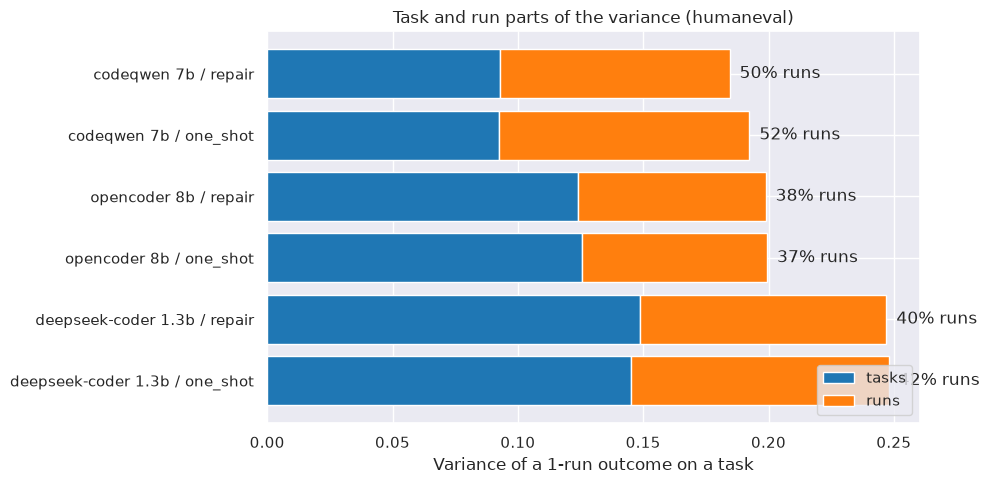

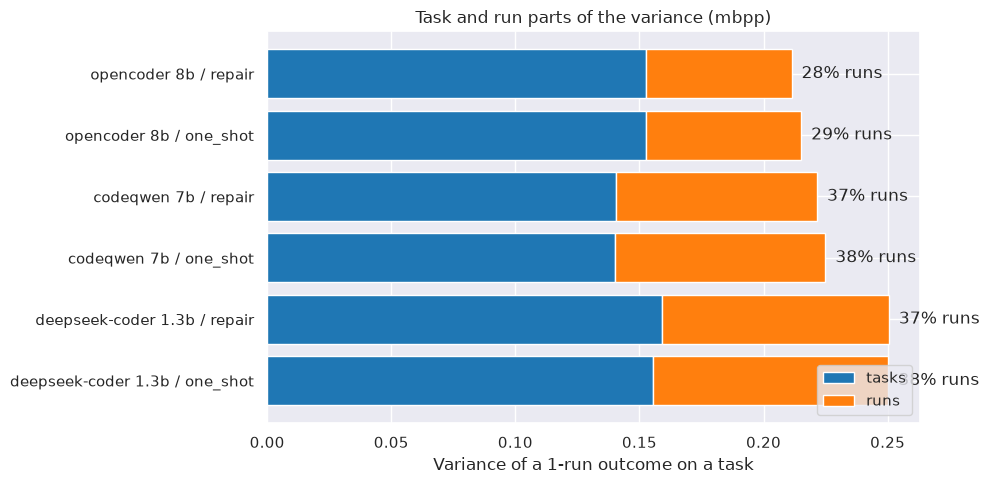

In [8]:
# Plot the task part and the run part of every agent.
for benchmark, table in variance.items():
    utils.plot_variance_parts(
        table,
        title=f"Task and run parts of the variance ({benchmark})",
        figsize=(10, 5),
    )

# Part 3: Which agents differ?

## Cell 3.1: Paired comparisons over tasks and runs

- The pre-registered family of comparisons:
  - The close pair (CodeQwen vs OpenCoder), for each scaffold
  - The weaker model (DeepSeek 1.3B) against each model of the pair
  - Repair against one-shot, for each model
- The Holm adjustment covers the whole family

In [9]:
# Compare the pre-registered pairs.
MODELS = {
    "deepseek": "deepseek-coder:1.3b-instruct-q4_K_M",
    "codeqwen": "codeqwen:7b-chat-v1.5-q4_K_M",
    "opencoder": "opencoder:8b",
}
pairs = []
for scaffold in ("one_shot", "repair"):
    pairs.append(
        ((MODELS["codeqwen"], scaffold), (MODELS["opencoder"], scaffold))
    )
    for strong in ("codeqwen", "opencoder"):
        pairs.append(
            ((MODELS[strong], scaffold), (MODELS["deepseek"], scaffold))
        )
for model in MODELS.values():
    pairs.append(((model, "repair"), (model, "one_shot")))
comparisons = utils.compare_agent_pairs(
    scores,
    pairs,
    source="local",
    benchmarks=BENCHMARKS,
    temperature=TEMPERATURE,
)

display(comparisons.round(4))
# Outcome: the close pair stays indistinguishable (Holm-adjusted p 0.26 to 1),
# even with OpenCoder 2.8 points ahead on MBPP+ at raw p 0.043 and 0.048; the
# weaker model trails by 16 to 20 points (adjusted p below 0.0001); repair beats
# one-shot in 4 of the 6 model and benchmark pairs.

,benchmark,agent_a,agent_b,gap,ci_low,ci_high,gap_run_0,p_value,p_holm,distinguishable
0,humaneval,codeqwen 7b / one_shot,opencoder 8b / one_shot,0.0146,-0.0329,0.0622,-0.0061,0.5287,1.0000,False
1,humaneval,codeqwen 7b / one_shot,deepseek-coder 1.3b / one_shot,0.1866,0.1305,0.2463,0.1829,0.0000,0.0000,True
2,humaneval,opencoder 8b / one_shot,deepseek-coder 1.3b / one_shot,0.1720,0.1244,0.2220,0.1890,0.0000,0.0000,True
3,humaneval,codeqwen 7b / repair,opencoder 8b / repair,0.0293,-0.0171,0.0768,0.0244,0.2005,0.6014,False
4,humaneval,codeqwen 7b / repair,deepseek-coder 1.3b / repair,0.1939,0.1354,0.2537,0.1951,0.0000,0.0000,True
5,humaneval,opencoder 8b / repair,deepseek-coder 1.3b / repair,0.1646,0.1159,0.2159,0.1707,0.0000,0.0000,True
6,humaneval,deepseek-coder 1.3b / repair,deepseek-coder 1.3b / one_shot,0.0085,0.0012,0.0183,0.0183,0.0519,0.2563,False
7,humaneval,codeqwen 7b / repair,codeqwen 7b / one_shot,0.0159,0.0073,0.0256,0.0305,0.0014,0.0115,True
8,humaneval,opencoder 8b / repair,opencoder 8b / one_shot,0.0012,-0.0073,0.0085,0.0000,0.7640,1.0000,False
9,mbpp,codeqwen 7b / one_shot,opencoder 8b / one_shot,-0.0280,-0.0550,-0.0005,-0.0238,0.0480,0.2563,False


# Part 4: How stable is a leaderboard from 1 run?

## Cell 4.1: Order of the agents in random 1-run leaderboards

- A leaderboard usually runs each agent once
- Picking 1 run per agent at random shows how often that order matches the
  order over all the runs

In [10]:
# Draw random 1-run leaderboards, on each benchmark.
matrices = {
    benchmark: utils.get_agent_matrices(
        scores, source="local", benchmark=benchmark, temperature=TEMPERATURE
    )
    for benchmark in BENCHMARKS
}
stability = {
    benchmark: utils.compute_ranking_stability(agent_matrices)
    for benchmark, agent_matrices in matrices.items()
}

for benchmark, (summary, flips) in stability.items():
    print("benchmark=", benchmark)
    print("summary=", summary.round(3).to_dict())
    display(flips.round(3))
# Outcome: only 18.5% (HumanEval+) and 25.3% (MBPP+) of the 1-run leaderboards
# keep the order of every pair; pairs up to 3 points apart swap 8% to 44% of the
# time, while the 16 to 21 point gaps to DeepSeek never swap.

benchmark= humaneval
summary= {'p_same_order': 0.185, 'mean_kendall_tau': 0.75}


,upper,lower,gap,p_flip
0,opencoder 8b / repair,opencoder 8b / one_shot,0.001,0.443
1,deepseek-coder 1.3b / repair,deepseek-coder 1.3b / one_shot,0.009,0.404
2,codeqwen 7b / one_shot,opencoder 8b / repair,0.013,0.364
3,codeqwen 7b / one_shot,opencoder 8b / one_shot,0.015,0.324
4,codeqwen 7b / repair,codeqwen 7b / one_shot,0.016,0.293
5,codeqwen 7b / repair,opencoder 8b / repair,0.029,0.118
6,codeqwen 7b / repair,opencoder 8b / one_shot,0.030,0.101
7,opencoder 8b / one_shot,deepseek-coder 1.3b / repair,0.163,0.000
8,opencoder 8b / repair,deepseek-coder 1.3b / repair,0.165,0.000
9,opencoder 8b / one_shot,deepseek-coder 1.3b / one_shot,0.172,0.000


benchmark= mbpp
summary= {'p_same_order': 0.253, 'mean_kendall_tau': 0.839}


,upper,lower,gap,p_flip
0,codeqwen 7b / repair,codeqwen 7b / one_shot,0.010,0.328
1,opencoder 8b / repair,opencoder 8b / one_shot,0.010,0.238
2,deepseek-coder 1.3b / repair,deepseek-coder 1.3b / one_shot,0.013,0.343
3,opencoder 8b / one_shot,codeqwen 7b / repair,0.018,0.158
4,opencoder 8b / one_shot,codeqwen 7b / one_shot,0.028,0.081
5,opencoder 8b / repair,codeqwen 7b / repair,0.028,0.082
6,opencoder 8b / repair,codeqwen 7b / one_shot,0.038,0.000
7,codeqwen 7b / one_shot,deepseek-coder 1.3b / repair,0.160,0.000
8,codeqwen 7b / repair,deepseek-coder 1.3b / repair,0.170,0.000
9,codeqwen 7b / one_shot,deepseek-coder 1.3b / one_shot,0.173,0.000


## Cell 4.2: Plot of the flip rate of each pair

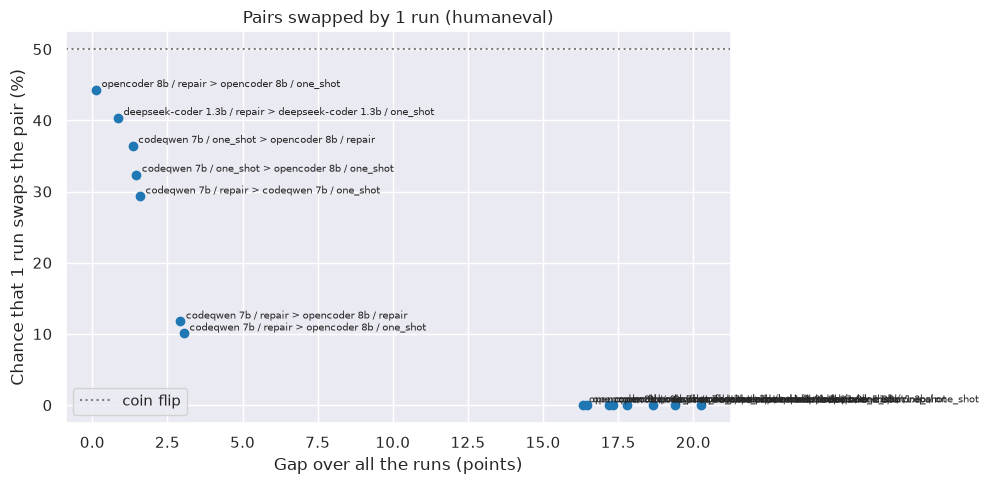

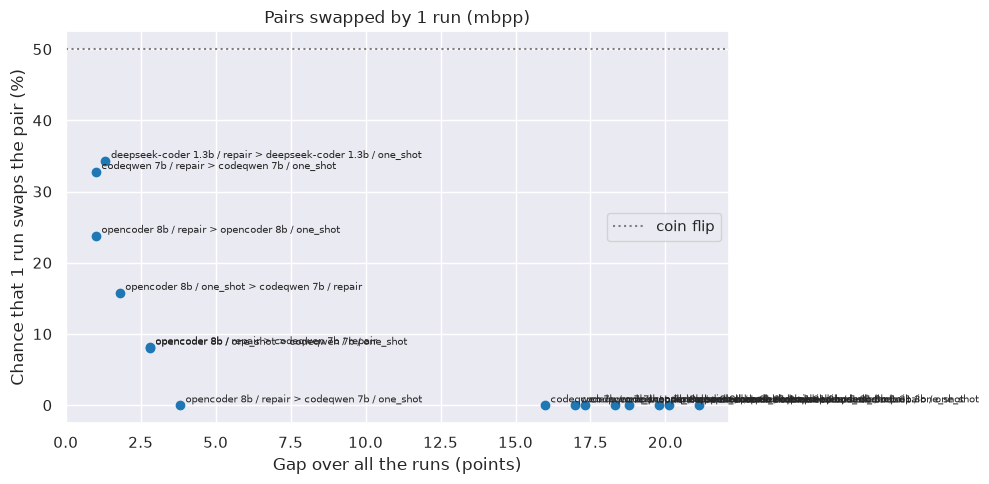

In [11]:
# Plot how often each pair swaps places, against its gap.
for benchmark, (_, flips) in stability.items():
    utils.plot_flip_rates(
        flips, title=f"Pairs swapped by 1 run ({benchmark})", figsize=(10, 5)
    )

## Cell 4.3: The 3 models alone

- Not in the pre-registration: an extra look at Cell 4.1
- A model with and without repair is almost the same agent, so those pairs
  swap often; keeping 1 scaffold at a time leaves the 3 distinct models

In [12]:
# Draw random 1-run leaderboards of the 3 models, for each scaffold.
for benchmark, agent_matrices in matrices.items():
    for scaffold in ("one_shot", "repair"):
        models_only = {
            label: matrix
            for label, matrix in agent_matrices.items()
            if label.endswith(scaffold)
        }
        summary, _ = utils.compute_ranking_stability(models_only)
        print("benchmark=", benchmark, "scaffold=", scaffold)
        print("summary=", summary.round(3).to_dict())
# Outcome: with the 3 models alone, 76% to 96% of the 1-run leaderboards keep
# the order; the swaps come from the close pair, and DeepSeek is never misplaced.

benchmark= humaneval scaffold= one_shot
summary= {'p_same_order': 0.76, 'mean_kendall_tau': 0.81}


benchmark= humaneval scaffold= repair
summary= {'p_same_order': 0.88, 'mean_kendall_tau': 0.92}


benchmark= mbpp scaffold= one_shot
summary= {'p_same_order': 0.958, 'mean_kendall_tau': 0.956}


benchmark= mbpp scaffold= repair
summary= {'p_same_order': 0.915, 'mean_kendall_tau': 0.943}


# Part 5: More runs or more tasks?

## Cell 5.1: Tasks needed for a gap, by runs per task

- More runs only shrink the run part of the variance, so for the same number
  of evaluations, more tasks always help more than more runs
- The curves use the variance parts of the close pair with the one-shot
  scaffold

In [13]:
# Split the variance of the gap of the close pair, on each benchmark.
parts = {
    benchmark: utils.compute_pair_variance_components(
        agent_matrices["codeqwen 7b / one_shot"],
        agent_matrices["opencoder 8b / one_shot"],
    )
    for benchmark, agent_matrices in matrices.items()
}

for benchmark, values in parts.items():
    print("benchmark=", benchmark)
    print("parts=", {key: round(value, 4) for key, value in values.items()})
# Outcome: for the close pair, the run part of the gap variance is about 3 times
# the task part (0.174 vs 0.053 on HumanEval+, 0.147 vs 0.046 on MBPP+), so more
# runs help, but the HumanEval+ gap of 1.5 points still needs about 3,200 tasks
# with 5 runs, and about 2,000 even with unlimited runs.

benchmark= humaneval
parts= {'sigma2_task_diff': 0.0534, 'sigma2_run_diff': 0.1738}
benchmark= mbpp
parts= {'sigma2_task_diff': 0.046, 'sigma2_run_diff': 0.1474}


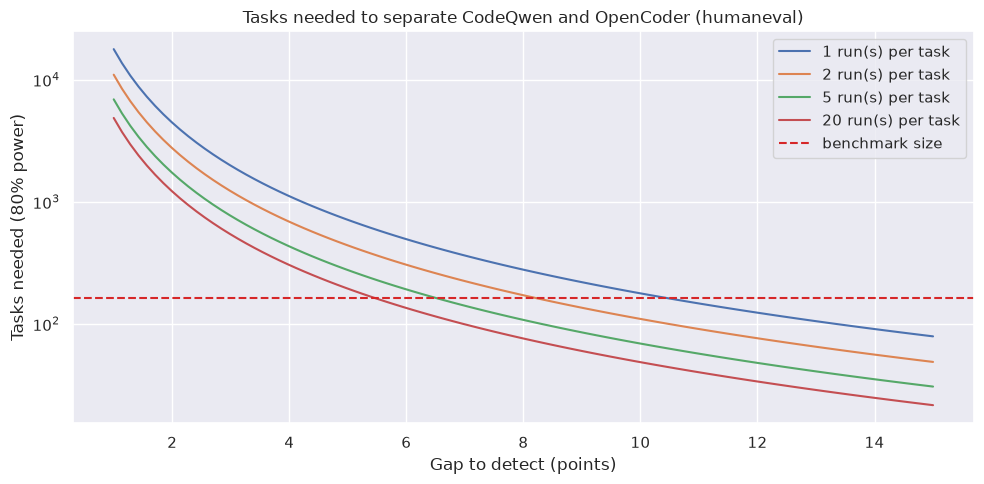

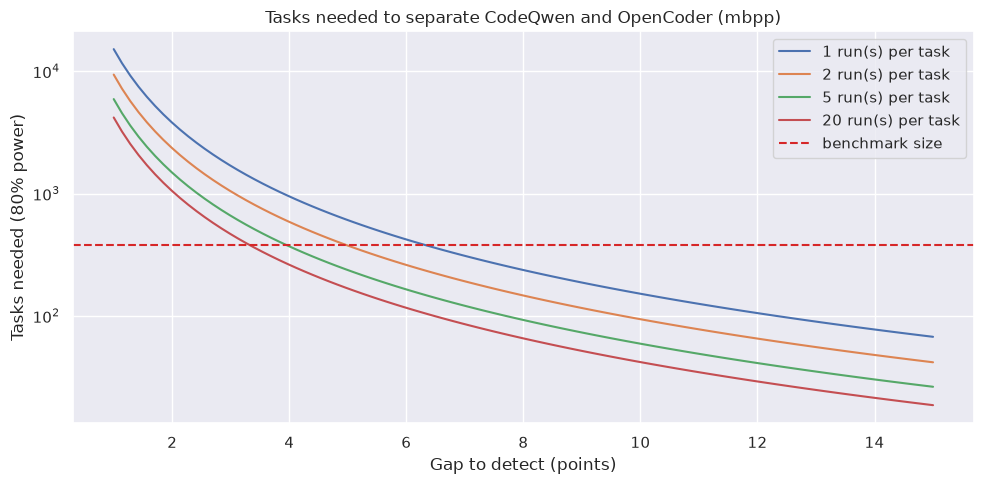

In [14]:
# Plot the tasks needed against the gap, for a few runs per task.
BENCHMARK_SIZES = {"humaneval": 164, "mbpp": 378}
for benchmark, values in parts.items():
    utils.plot_min_tasks_vs_runs(
        values["sigma2_task_diff"],
        values["sigma2_run_diff"],
        n_tasks=BENCHMARK_SIZES[benchmark],
        title=f"Tasks needed to separate CodeQwen and OpenCoder ({benchmark})",
        figsize=(10, 5),
    )

# Part 6: Does temperature change run luck?

## Cell 6.1: Run variance of the public samples at 2 temperatures

- EvalPlus published 200 samples per HumanEval+ task for 8 models at
  temperatures 0.2 and 0.8, and the first 50 per task are scored here
- Each sample of a task plays the role of 1 run

In [15]:
# Compare the run variance of every public model at the 2 temperatures.
temperature_table = utils.compute_temperature_table(
    scores, benchmark="humaneval"
)

display(temperature_table.round(4))
# Outcome: from temperature 0.2 to 0.8 the run variance grows 1.8 to 3.0 times,
# and the run share goes from 15% to 30% at 0.2 to 42% to 55% at 0.8; only 4 of
# the 8 models reach the factor of 2 that P7 predicted.

,score_low,sigma2_run_low,run_share_low,score_high,sigma2_run_high,run_share_high,run_ratio
model,,,,,,,
phind-code-llama-34b-v2,0.6751,0.0334,0.1513,0.6194,0.1003,0.4239,3.0060
code-llama-34b,0.4401,0.0734,0.2964,0.3795,0.1290,0.5463,1.7587
code-llama-13b,0.3813,0.0568,0.2397,0.3427,0.1178,0.5214,2.0729
code-llama-7b,0.3483,0.0499,0.2188,0.2865,0.1068,0.5209,2.1397
codet5p-16b,0.2768,0.0472,0.2345,0.2254,0.0842,0.4808,1.7851
codegen-16b,0.2754,0.0397,0.1980,0.1945,0.0730,0.4643,1.8381
starcoder,0.2743,0.0451,0.2253,0.2056,0.0879,0.5369,1.9517
mistral-7b,0.2377,0.0390,0.2144,0.1972,0.0846,0.5327,2.1665


## Cell 6.2: Plot of the run variance at the 2 temperatures

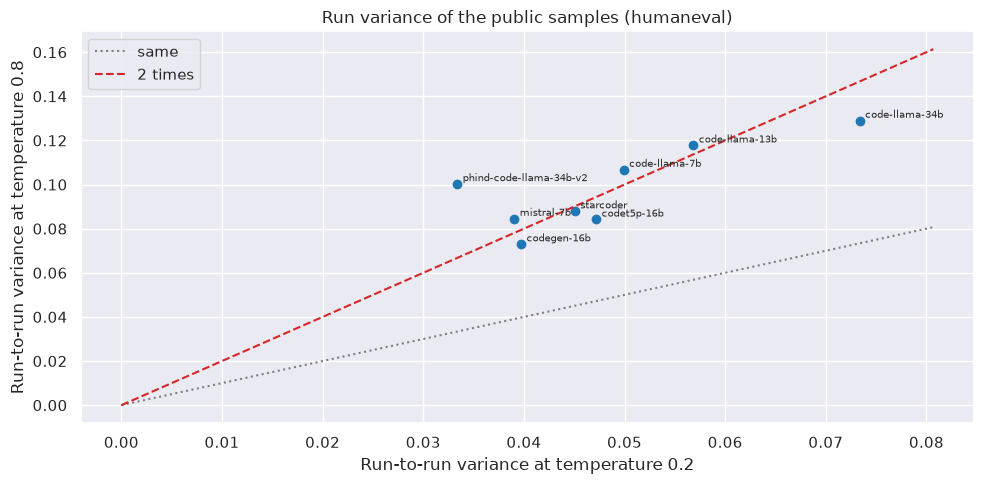

In [16]:
# Plot the run variance at 0.8 against the one at 0.2.
utils.plot_temperature_effect(
    temperature_table,
    title="Run variance of the public samples (humaneval)",
    figsize=(10, 5),
)

## Cell 6.3: 1-run leaderboards of the public models

- Not in the pre-registration: an extra look
- The same random 1-run leaderboards as in Part 4, for the 8 public models
  sampled at both temperatures

In [17]:
# Draw random 1-run leaderboards of the public models, at each temperature.
public_stability = {}
for temperature in (0.2, 0.8):
    public_matrices = utils.get_agent_matrices(
        scores, source="evalplus", benchmark="humaneval", temperature=temperature
    )
    # Keep the models of Cell 6.1, so both temperatures rank the same models.
    public_matrices = {
        label: matrix
        for label, matrix in public_matrices.items()
        if label.split(" / ")[0] in temperature_table.index
    }
    public_stability[temperature] = utils.compute_ranking_stability(
        public_matrices
    )

for temperature, (summary, _) in public_stability.items():
    print("temperature=", temperature)
    print("summary=", summary.round(3).to_dict())
# Outcome: with the same 8 models, 23.2% of the 1-run leaderboards keep the
# order of every pair at temperature 0.2, and only 13.3% at 0.8.

temperature= 0.2
summary= {'p_same_order': 0.232, 'mean_kendall_tau': 0.882}
temperature= 0.8
summary= {'p_same_order': 0.133, 'mean_kendall_tau': 0.858}


# Part 7: Were the predictions right?

## Cell 7.1: Predictions against results

- Each prediction of `preregistration.md` is checked with the rule committed
  before any scoring, in `check_predictions()`

In [18]:
# Check every pre-registered prediction.
predictions = utils.check_predictions(
    validation=validation,
    score_table=utils.compute_score_table(scores),
    variance_tables=variance,
    comparisons=comparisons,
    flaky_share=flaky_share,
    temperature_table=temperature_table,
    weak_model=MODELS["deepseek"],
    pair_models=(MODELS["codeqwen"], MODELS["opencoder"]),
)

display(predictions)
# Outcome: 4 of the 7 predictions hold (P1, P2, P4, P6); P3 fails because run
# luck is above 40% for 3 agents on HumanEval+ (up to 52%), P5 because CodeQwen
# gains more from repair on HumanEval+, and P7 because only 4 of the 8 public
# models double their run variance.

,prediction,observed,holds
P1,The close pair is not distinguishable,"0 of 4 comparisons distinguishable, smallest H...",True
P2,The weaker model is distinguishable from the pair,8 of 8 comparisons distinguishable with the we...,True
P3,Runs are 10% to 40% of the variance of 1 run,"9 of 12 inside, from 28% to 52%",False
P4,Greedy scores are within 5 points of the publi...,"6 of 6 within 5 points, largest gap +1.9 point...",True
P5,"Repair helps every model, more on MBPP+","gains from +0.1 to +1.6 points, larger on MBPP...",False
P6,Less than 1% of the answers are flaky,0.00% of the answers changed,True
P7,Run variance at 0.8 is at least 2 times that a...,"4 of 8 models at least 2 times, ratio from 1.7...",False


# Part 8: Takeaways and next steps

## Takeaways

- The harness reproduces the published EvalPlus scores: the 6 greedy scores
  are within 2 points, even with 4-bit weights, and no test is flaky
- At temperature 0.8, run-to-run luck is a large part of the noise
  - It is 28% to 52% of the variance of a 1-run outcome for our 6 agents
  - In the public samples it is 42% to 55% at 0.8, against 15% to 30% at 0.2
- A 1-run leaderboard often has the order wrong
  - Only 18.5% (HumanEval+) and 25.3% (MBPP+) of them keep the order of all 6
    agents, mostly because a model with and without repair is almost the same
    agent
  - With the 3 models alone, 76% to 96% keep the order, and the close pair is
    the one that swaps
  - On HumanEval+, the gap of the close pair in the 5 runs goes from -2.4 to
    +6.1 points, so 1 run can show either model ahead
  - In the public samples, the share drops from 23.2% at temperature 0.2 to
    13.3% at 0.8
- The close pair cannot be told apart, even with 5 runs per task, while the
  weaker model is 16 to 20 points behind and always distinguishable
  - The HumanEval+ gap of the pair, 1.5 points, would need about 3,200 tasks
    with 5 runs, and about 2,000 even with unlimited runs
- Repair helps a little: +0.1 to +1.6 points, significant in 4 of 6 cases
- 4 of the 7 pre-registered predictions held; P3 (run share), P5 (repair), and
  P7 (temperature) did not

## Next steps

- Combine the run share measured here with the SWE-bench Verified intervals,
  to see how much of that leaderboard a rerun would reorder
- Milestone 3: split-half and cross-benchmark rank correlations, and a 2PL IRT
  model of task difficulty
- Milestone 4: the winner's curse of picking the best of several attempts